Step 1: Import Libraries

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

 Step 2: Load the dataset

In [35]:
df = pd.read_csv("uber.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())


First 5 rows:
    distance   duration  passengers        fare
0  19.127769  40.749108           3  324.056778
1  27.019200  74.088630           4  442.560731
2  23.494885  64.408146           2  418.355322
3   7.531009  16.647355           4  164.248757
4   9.704822  25.735889           1  179.663582

Dataset Shape:
(500, 4)

Column Names:
Index(['distance', 'duration', 'passengers', 'fare'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   distance    500 non-null    float64
 1   duration    500 non-null    float64
 2   passengers  500 non-null    int64  
 3   fare        500 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 15.8 KB
None


Step 3: Preprocess the dataset

In [37]:
# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Remove missing values
df.dropna(inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

print("\nDataset after preprocessing:")
print(df.head())

print("\nUpdated Dataset Shape:")
print(df.shape)


Missing Values:
distance      0
duration      0
passengers    0
fare          0
dtype: int64

Dataset after preprocessing:
    distance   duration  passengers        fare
0  19.127769  40.749108           3  324.056778
1  27.019200  74.088630           4  442.560731
2  23.494885  64.408146           2  418.355322
3   7.531009  16.647355           4  164.248757
4   9.704822  25.735889           1  179.663582

Updated Dataset Shape:
(500, 4)


C:\Users\tanis\AppData\Local\Temp\ipykernel_6980\3756805010.py:6: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)
C:\Users\tanis\AppData\Local\Temp\ipykernel_6980\3756805010.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


Step 4: Identify outliers using Boxplot

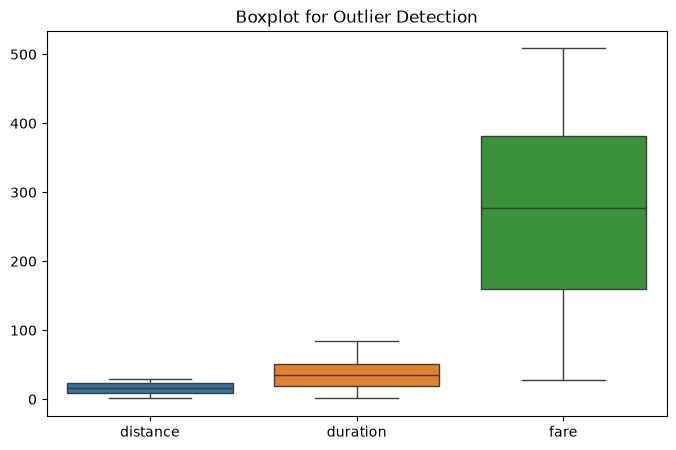

In [38]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[["distance", "duration", "fare"]])

plt.title("Boxplot for Outlier Detection")
plt.show()


Step 5: Remove outliers using IQR method

In [39]:
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df = df[
    (df["fare"] >= lower_limit) &
    (df["fare"] <= upper_limit)
]

print("\nDataset after removing outliers:")
print(df.shape)


Dataset after removing outliers:
(500, 4)


Step 6: Check correlation

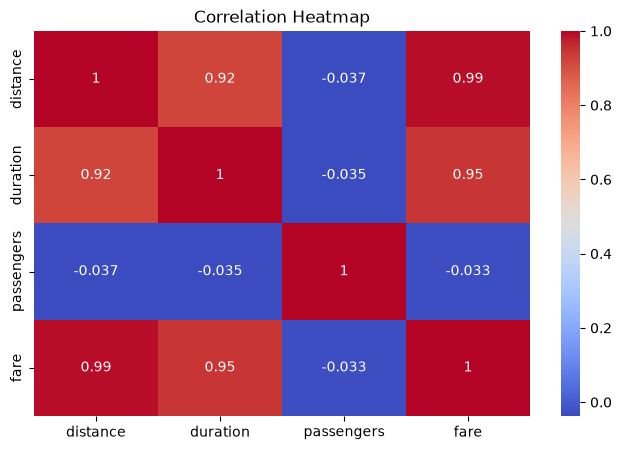


Correlation with Fare:
fare          1.000000
distance      0.988463
duration      0.945592
passengers   -0.032518
Name: fare, dtype: float64


In [40]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

print("\nCorrelation with Fare:")
print(df.corr()["fare"].sort_values(ascending=False))

 Step 7: Select independent and dependent variables

In [41]:
# Independent variables
X = df[["distance", "duration", "passengers"]]

# Dependent variable
y = df["fare"]

Step 8: Split the dataset

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


Step 9: Standardize the data

In [43]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

Step 10: Implement Linear Regression

In [44]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

linear_predictions = linear_model.predict(X_test_scaled)

Step 11: Implement Ridge Regression

In [45]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

ridge_predictions = ridge_model.predict(X_test_scaled)

Step 12: Implement Lasso Regression

In [46]:
lasso_model = Lasso(alpha=0.01)

lasso_model.fit(X_train_scaled, y_train)

lasso_predictions = lasso_model.predict(X_test_scaled)

 Step 13: Evaluate the models

In [48]:
def evaluate_model(name, actual, predicted):

    r2 = r2_score(actual, predicted)

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    print("\n", name)

    print("R2 Score:", r2)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)

    return [name, r2, mae, mse, rmse]


# Evaluate Linear Regression
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

# Evaluate Ridge Regression
results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        ridge_predictions
    )
)

# Evaluate Lasso Regression
results.append(
    evaluate_model(
        "Lasso Regression",
        y_test,
        lasso_predictions
    )
)


 Linear Regression
R2 Score: 0.9853403274878337
MAE: 12.364170243192735
MSE: 233.5238238317249
RMSE: 15.281486309640332

 Ridge Regression
R2 Score: 0.9851954015099832
MAE: 12.38209703375725
MSE: 235.83244760842376
RMSE: 15.356837161617094

 Lasso Regression
R2 Score: 0.9853457527292195
MAE: 12.362451956372224
MSE: 233.43740149776323
RMSE: 15.278658367074094


Step 14: Compare model performance

In [49]:
comparison = pd.DataFrame(
    results,
    columns=["Model", "R2", "MAE", "MSE", "RMSE"]
)

print("\nModel Comparison:")
print(comparison)


Model Comparison:
               Model        R2        MAE         MSE       RMSE
0  Linear Regression  0.985340  12.364170  233.523824  15.281486
1   Ridge Regression  0.985195  12.382097  235.832448  15.356837
2   Lasso Regression  0.985346  12.362452  233.437401  15.278658


Step 15: Visualize R2 Score

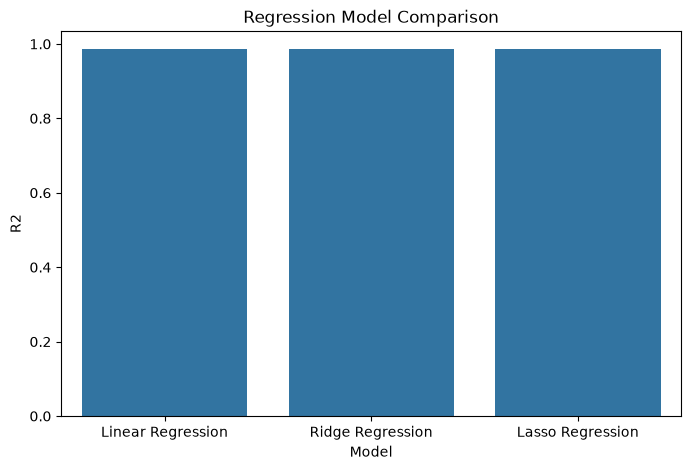

In [50]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x="Model",
    y="R2",
    data=comparison
)

plt.title("Regression Model Comparison")
plt.show()


Step 16: Actual vs Predicted Fare

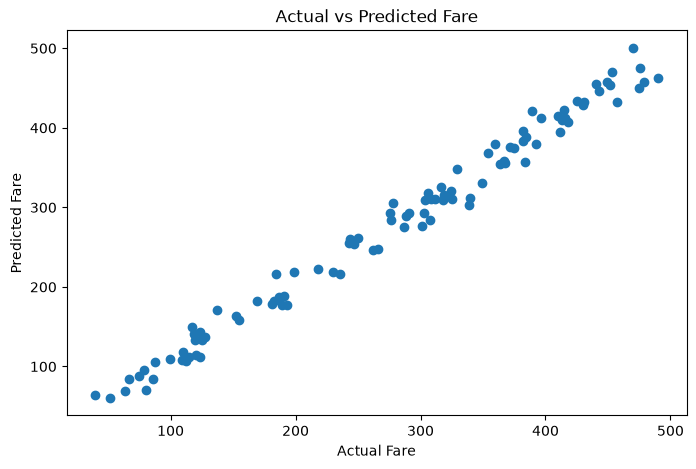

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    linear_predictions
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Fare")

plt.show()

Step 17: Predict fare for a new ride

In [52]:
new_ride = pd.DataFrame({
    "distance": [15],
    "duration": [30],
    "passengers": [2]
})

# Standardize new ride data
new_ride_scaled = scaler.transform(new_ride)

# Predict fare
predicted_fare = linear_model.predict(new_ride_scaled)

print("\nPredicted Uber Fare:")
print(predicted_fare[0])


Predicted Uber Fare:
255.1654838847956
